# Experiment on Gradient-based Optimization Algorithm

In this notebook, we do some experiment on various gradient-based optimization algorithm to study their stability, convergence, scalability and other possible interesting behaviour of the algorithm. The experiment will be done by working on the exercises from Steve Brunton's book _Optimization Bootcamp_.

We will study and experiment with full-batch gradient descent (GD), GD with momentum, one-sample and mini-batch stochastic gradient descent (SGD). Then (possibly) we will study and experiment with ADAM as well.

## Full-Batch Gradient Descent

### Exercise 2-2 (p.85)
Goal: $\textit{To observe and comprehend the effect of various step size value on GD algorithm.}$

In this exercise, we will start our experiment by apply GD algorithm to a simple one-dimensional quadratic objective function:

\begin{equation}
    f(x) = x^2 + 2x + 5
    \tag{1.1}
\end{equation}

The minimum of equation (1.1) is $f(x^*)=4$, where $x^*=-1$.



In [3]:
import numpy as np
import matplotlib.pyplot as plt

Define the quadratic objective function and the GD algorithm:

In [2]:
# Define the quadratic objective function.
def quadratic_objective(x):
    return x**2 + 2*x + 5

# Define the GD algorithm. The function return x_k and f(x_k).
def gradient_descent(x0, step_size, max_iter):
    xval = [np.array(x0)] # Initialize with x0 for plotting
    fval = [quadratic_objective(np.array(x0))] # Initialize with f(x0) for plotting. 
    x = np.array(x0, dtype=float) # Initialize with x0 for iteration.

    for _ in range(max_iter):
        grad = 2*x + 2  # Compute the gradient of objective function.
        x = x - step_size * grad  # Update x using the gradient descent step.
        xval.append(x.copy())  # Store the current x for plotting.
        fval.append(quadratic_objective(x))  # Store the current function value for plotting.
    return np.array(xval), np.array(fval)  # Return the arrays of x values and function values for plotting.

Run GD algorithm for various step-size $\gamma$:

In [3]:
x0 = np.array([5.0]) # Initial point.
gamma_large = 1 # Large step size.
gamma_small = 0.01 # Small step size.
gamma_good = 0.4 # Good step size.
N = 20 # Maximum iterations.

# Run gradient descent for each step size:
x_large, f_large = gradient_descent(x0, gamma_large, N)
x_small, f_small = gradient_descent(x0, gamma_small, N)
x_good, f_good = gradient_descent(x0, gamma_good, N)

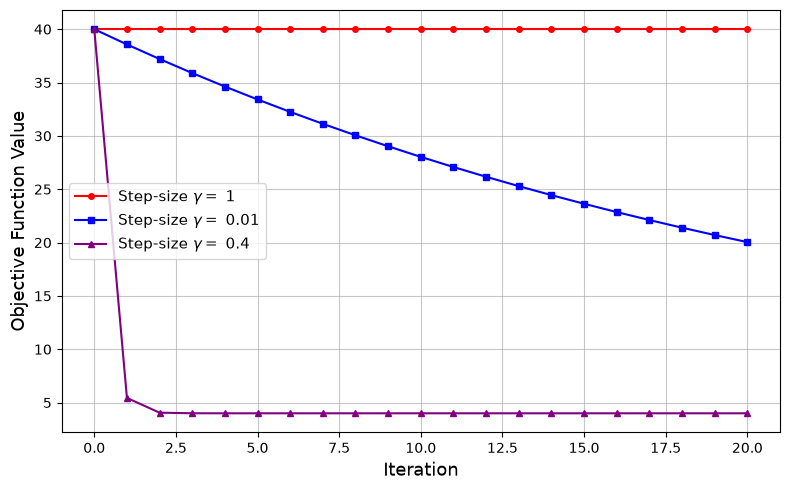

In [4]:
# Plot objective function value against iteration
plt.figure(figsize=(8, 5))

plt.plot(f_large, 'o-', markersize=4, color='red',
         label=r'Step-size $\gamma =$ 1')

plt.plot(f_small, 's-', markersize=4, color='blue',
         label=r'Step-size $\gamma =$ 0.01')

plt.plot(f_good, '^-', markersize=4, color='purple',
         label=r'Step-size $\gamma =$ 0.4')

plt.xlabel('Iteration', fontsize=13)
plt.ylabel('Objective Function Value', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.7)
plt.tight_layout()
plt.show()

The plot above shows some interesting results. For step-size $\gamma=1$, the iteration is nearly unstable. It is neither converge nor diverge, but stuck at the initial function value. This suggest that $\gamma=1$ is too large. For step-size $\gamma=0.01$, the iteration seems to converge to the minimum but it is way too slow. This indicates that $\gamma=0.01$ is too small. The last value, $\gamma=0.4$ show fast convergence at the beginning and then reach the minimum after two iteration (approximately). Hence for this simple case, step-size $\gamma=0.4$ is the optimal value among three step-size values the we experimented with.

This simple experiment confirm our mathematical analysis that step-size determine the stability and convergence rate of the GD algorithm. If step-size is too large, the iteration will be barely stable or even unstable. On the other hand, if step-size is too small, the iteration will converge too slowly. The optimal step-size lies somewhere between the two and it lead to fast convergence.

### Exercise 2-1 (p.85) and Exercise 2-9 (p.86).
Goal: $\textit{To observe and comprehend how stability and convergence speed of GD algorithm is influenced by:}$ 
- $\textit{optimal step size. }$
- $\textit{Step size on and close to the stability boundary.}$

In this experiment, we will explore the effect of step-size on stability of gradient descent in a more sophisticated manner. Consider a two-dimensional quadratic objective function:

\begin{aligned}
f(\mathbf{x}) = \frac{1}{2}\mathbf{x}^T A \mathbf{x}
\qquad \text{where} \qquad
A = \begin{bmatrix}
2 & 1 \\
1 & 3
\end{bmatrix}
\tag{1.2}
\end{aligned}

Note that equation (1.2) is a convex quadratic function since the Hessian matrix $A$ is positive definite. The minimum value is attained at the origin, i.e. $\mathbf{x}^{*} = 0$. Here are some interesting exercises to experiment with:

(a) Compute the maximum step-size $\gamma_{max}$ where the iteration goes unstable, then simulate. Is the stability boundary as predicted ?

(b) Compute the optimal step-size $\gamma^*$, then simulate.

(c) Test the gradient descent with $\gamma$ just above and below the maximum stability boundary.

Before we answer the above question, it is important to stress out that the stability of GD depend both on the step-size $\gamma$ and the eigenvalues of the Hessian matrix $A$. Since the matrix $A$ is given, what we can control is the choice of step-size $\gamma$. 

Recall that the range of stable step-size $\gamma$ for GD algorithm obey the following inequality:

\begin{equation}
0 < \gamma < \frac{2}{\lambda_{\max}(A)}
\tag{1.3}
\end{equation}

The set of stable step size $\gamma$ form an open interval $ (0,2/\lambda_{\max}(A) $ where $0$ is the infimum or greates lower bound (GLB) and $2/\lambda_{\max}(A)$ is the supremum or least upper bound (LUB). Note that inequality (1.3) tell us that step-size $\gamma$ has to be positive (there will no improvement with zero step-size). It is interesting to look closely at the LUB:

\begin{equation}
    \gamma_{sup} = \frac{2}{\lambda_{\max}(A)} \propto \frac{1}{\lambda_{max}(A)}
    \tag{1.4}
\end{equation}

The eigenvalues $\lambda_i$ of the Hessian matrix $A$ represent the curvature of the function $f$ in the eigendirection. Thus, formula (1.4) tell us that when the curvature is large, then the range of stable step-size $\gamma$ is tight. Vice versa, when the curvature is small, then the range of stable step-size $\gamma$ is wide. 

Intuitively, formula (1.4 ) makes very much sense. When the curvature is large, overly large step-size will lead to barely stable or unstable behaviour where the gradient step overshoot the minimum and oscillate. Thus, the range of step-size should be narrow to avoid instability. On the contrary, when the curvature is small, then it is safe to take large step toward the minimum. Hence, the range of step-size can be wide for faster convergence.

To answer (a), we need to find $\lambda_{\max}(A)$, then calculate $\gamma_{sup}$:

In [5]:
# Define the parameters for the quadratic objective function (1.2).
A = np.array([[2,1],[1,3]]) # Positive definite Hessian matrix A.
b = np.array([0,0]) # Linear term.
c = 0 # Constant term.

In [6]:
# Calculate maximum step-size based on the eigenvalues of A.
eigenvalues = np.linalg.eigvalsh(A)
gamma_max = 2 / eigenvalues.max()

print("Eigenvalues:", eigenvalues)
print("Maximum step size:", gamma_max)

Eigenvalues: [1.38196601 3.61803399]
Maximum step size: 0.552786404500042


The maximum eigenvalue $\lambda_{max}(A) \approx 3.618$ and maximum step-size $\gamma_{sup} \approx 0.5527$. Now we need to simulate this results.

In [7]:
# Define the quadratic objective function.
def quadratic_objective(X,A,b,c):
    return 0.5 * X.T @ A @ X + b.T @ X + c

# Define the GD algorithm. The function return x_k and f(x_k).
def gradient_descent(A, b, c, x0, step_size, max_iter):
    xval = [np.array(x0)] # Initialize with x0 for plotting
    fval = [quadratic_objective(np.array(x0), A, b, c)] # Initialize with f(x0) for plotting. 
    x = np.array(x0, dtype=float) # Initialize with x0 for iteration.

    for _ in range(max_iter):
        grad = A @ x + b  # Compute the gradient of objective function.
        x = x - step_size * grad  # Update x using the gradient descent step.
        xval.append(x.copy())  # Store the current x for plotting.
        fval.append(quadratic_objective(x, A, b, c))  # Store the current function value for plotting.
    return np.array(xval), np.array(fval)  # Return the arrays of x values and function values for plotting.

In [8]:
# Set the input for the gradient descent algorithm.
x0 = np.array([-2.0,0.0]) # Initial point.
N = 50 # Maximum iterations.

# Run gradient descent for each step size:
x_max, f_max = gradient_descent(A, b, c, x0, gamma_max, N)

Plot the trajectory of $x_k$ on the level sets of the objective function:

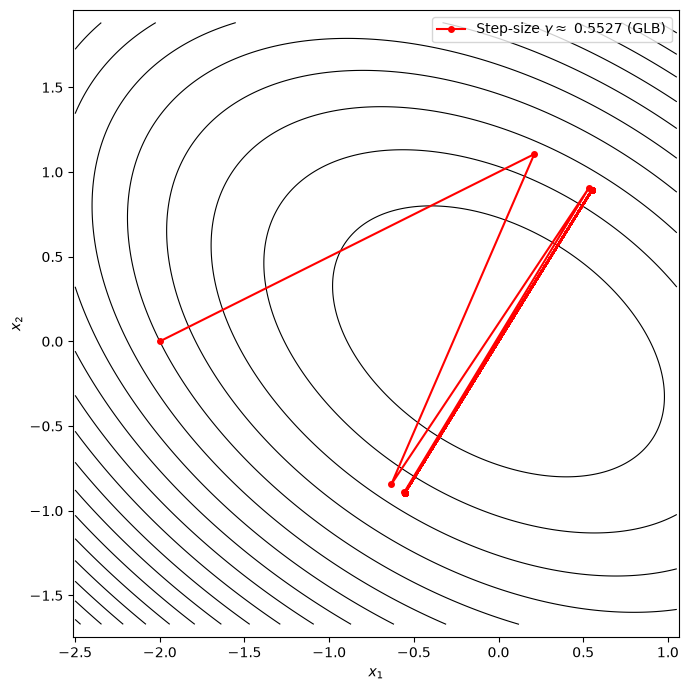

In [11]:
# Convert trajectories to NumPy arrays
def prepare_trajectory(xval):
    xval = np.asarray(xval)
    if xval.ndim == 2 and xval.shape[0] == 2 and xval.shape[1] != 2:
        xval = xval.T
    return xval

x_max = prepare_trajectory(x_max)

# Use matching square bounds for the contour grid and displayed axes.
all_x = np.vstack([x_max])
x_center = (all_x[:, 0].min() + all_x[:, 0].max()) / 2
y_center = (all_x[:, 1].min() + all_x[:, 1].max()) / 2
half_range = 0.5 * max(np.ptp(all_x[:, 0]), np.ptp(all_x[:, 1])) + 0.5
xmin, xmax = x_center - half_range, x_center + half_range
ymin, ymax = y_center - half_range, y_center + half_range

xx = np.linspace(xmin, xmax, 300)
yy = np.linspace(ymin, ymax, 300)
X, Y = np.meshgrid(xx, yy)

# Evaluate the quadratic objective function on the grid
F = (0.5 * (A[0, 0] * X**2
            + (A[0, 1] + A[1, 0]) * X * Y
            + A[1, 1] * Y**2)
     + b[0] * X + b[1] * Y + c)

# Plot contours
plt.figure(figsize=(7, 7))
plt.contour(X, Y, F, levels=20, colors='black',
            linewidths=0.8)

# Plot gradient descent trajectories
plt.plot(x_max[:, 0], x_max[:, 1], 'o-',
         color='red', markersize=4,
         label=r'Step-size $\gamma \approx$ 0.5527 (GLB)')

plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.axis('equal')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

The plot above shows that, starting from initial condition, the GD algorithm initially make a large jump into a much lower level set. This is obviously caused by the large step-size $\gamma_{sup}$. What happen next is really interesting. After the first few iteration, GD algorithm cannot move to a lower level set. Instead, it oscillates back and forth around the minimum. Thus, for step-size $\gamma_{sup}$, the GD algorithm shows the behaviour that is on the stability boundary, in the sense that it does not converge nor diverge. This behaviour confirm that the step-size $\gamma_{sup}$ is indeed on the stability boundary (GLB), i.e. to have a stable behaviour, the GD algorithm must have step-size $\gamma < \gamma_{sup}$.

Plot the value of objective function over N iteration:

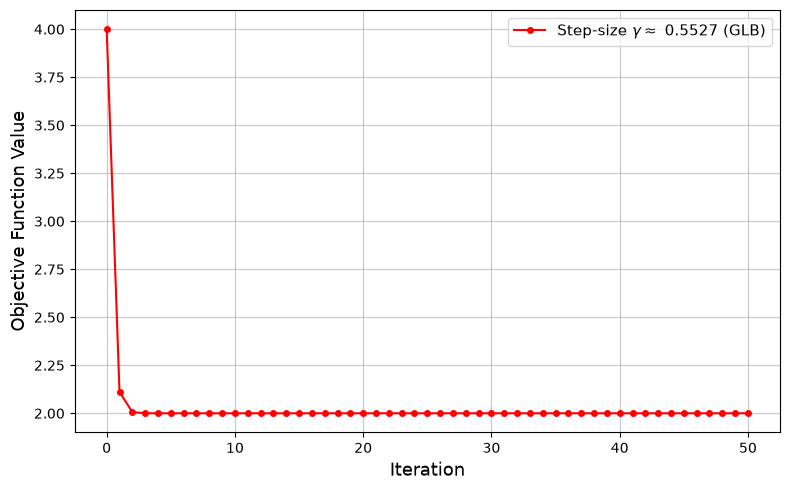

In [13]:
# Plot objective function value against iteration
plt.figure(figsize=(8, 5))

plt.plot(f_max, 'o-', markersize=4, color='red',
         label=r'Step-size $\gamma \approx$ 0.5527 (GLB)')

plt.xlabel('Iteration', fontsize=13)
plt.ylabel('Objective Function Value', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.7)
plt.tight_layout()
plt.show()

The plot above is consistent with the level set plot. Initial iteration improve significantly, then the objective value function stuck above the minimum value (precisely at $f(x)=2$). Again this confirm that the GD algorithm show the behaviour on the stability boundary when we use the step-size $\gamma_{sup}$. This answer (a).

To answer (b) we need to calculate the optimal step-zize $\gamma^*$. Recall that the optimal step-zize $\gamma^*$ of GD algorithm with convex quadratic objective function is given by:

\begin{equation}
    \gamma^* = \frac{2}{\lambda_{min}(A) + \lambda_{max}(A)}
    \tag{1.5}
\end{equation}

Thus, we need to calculate both $\lambda_{min}$ and $\lambda_{max}$ of the Hessian matrix $A$ first, then calculate the optimal step-size $\gamma^*$ according to equation (1.5).

In [15]:
# Calculate optimal step-size based on the eigenvalues of A.
eigenvalues = np.linalg.eigvalsh(A)
gamma_opt = 2 / (eigenvalues.min() + eigenvalues.max())  # Optimal step size for gradient descent.

print("Minimum eigenvalues:", eigenvalues.min())
print("Maximum eigenvalues:", eigenvalues.max())
print("Optimal step-size:", gamma_opt)

Minimum eigenvalues: 1.381966011250105
Maximum eigenvalues: 3.618033988749895
Optimal step-size: 0.4


The optimal step-size $\gamma^*=0.4$. Now lets simulate the GD algorithm.

In [27]:
# Run gradient descent for each step size:
N = 20 # Maximum iterations.
gamma_small = 0.1 # Small step size.

x_opt, f_opt = gradient_descent(A, b, c, x0, gamma_opt, N)
x_small, f_small = gradient_descent(A, b, c, x0, gamma_small, N)

Plot the trajectory of $x_k$ on the level sets of the objective function:

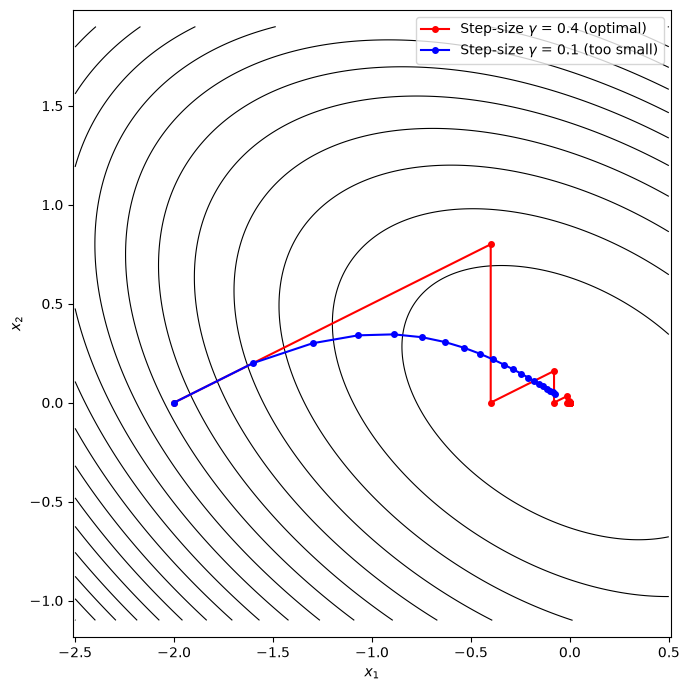

In [28]:
# Convert trajectories to NumPy arrays
def prepare_trajectory(xval):
    xval = np.asarray(xval)
    if xval.ndim == 2 and xval.shape[0] == 2 and xval.shape[1] != 2:
        xval = xval.T
    return xval

x_opt = prepare_trajectory(x_opt)
x_small = prepare_trajectory(x_small)

# Use matching square bounds for the contour grid and displayed axes.
all_x = np.vstack([x_opt, x_small])
x_center = (all_x[:, 0].min() + all_x[:, 0].max()) / 2
y_center = (all_x[:, 1].min() + all_x[:, 1].max()) / 2
half_range = 0.5 * max(np.ptp(all_x[:, 0]), np.ptp(all_x[:, 1])) + 0.5
xmin, xmax = x_center - half_range, x_center + half_range
ymin, ymax = y_center - half_range, y_center + half_range

xx = np.linspace(xmin, xmax, 300)
yy = np.linspace(ymin, ymax, 300)
X, Y = np.meshgrid(xx, yy)

# Evaluate the quadratic objective function on the grid
F = (0.5 * (A[0, 0] * X**2
            + (A[0, 1] + A[1, 0]) * X * Y
            + A[1, 1] * Y**2)
     + b[0] * X + b[1] * Y + c)

# Plot contours
plt.figure(figsize=(7, 7))
plt.contour(X, Y, F, levels=20, colors='black',
            linewidths=0.8)

# Plot gradient descent trajectories
plt.plot(x_opt[:, 0], x_opt[:, 1], 'o-',
         color='red', markersize=4,
         label=r'Step-size $\gamma$ = 0.4 (optimal)')

plt.plot(x_small[:, 0], x_small[:, 1], 'o-',
         color='blue', markersize=4,
         label=r'Step-size $\gamma$ = 0.1 (too small)')

plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.axis('equal')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

We compare the optimal step-size $\gamma^*=0.4$ with a smaller step-size $\gamma=0.1$. The level set plot above shows that using the optimal step-size $\gamma^*$ indeed guarantee stability and fast convergence of the GD algorithm. Initially, the iteration take large step toward lower level set since the gradient is large when the point $x_k$ is far from the optimal point $x^*=0$. As $x_k$ gets closer to the optimal point, the gradient gets smaller which cause the iteration to take smaller steps. With smaller step-size $\gamma=0.1$, the GD algorithm also to converge to the minimum but much slower.

Plot the value of objective function over $N$ iteration:

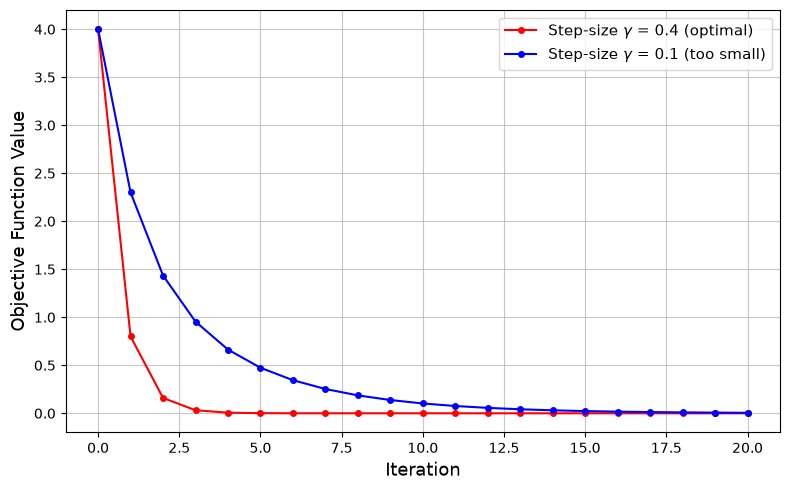

In [29]:
# Plot objective function value against iteration
plt.figure(figsize=(8, 5))

plt.plot(f_opt, 'o-', markersize=4, color='red',
         label=r'Step-size $\gamma$ = 0.4 (optimal)')

plt.plot(f_small, 'o-', markersize=4, color='blue',
         label=r'Step-size $\gamma$ = 0.1 (too small)')

plt.xlabel('Iteration', fontsize=13)
plt.ylabel('Objective Function Value', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.7)
plt.tight_layout()
plt.show()

The plot above shows how the GD algorithm with optimal step-size $\gamma^*$ converge to the minimum in only four iterations. This again confirm the optimality of $\gamma^*$. On the other hand, with smaller step-size $\gamma=0.1$, the GD algorithm converge to the minimum but about three times slower. This answer (b).

To answer (c), we need to set two step size: one slightly above $\gamma_{\sup}$, and the other one slightly below $\gamma_{\sup}$. Then we run the GD algorithm to see the effect of step size.

In [30]:
# Set the step-sizes above and below the maximum step-size.
gamma_above = gamma_max + 0.01  # Step-size above the maximum step-size.
gamma_below = gamma_max - 0.01  # Step-size below the maximum step-size.

print("Step-size above maximum:", gamma_above)
print("Step-size below maximum:", gamma_below)

Step-size above maximum: 0.562786404500042
Step-size below maximum: 0.542786404500042


In [44]:
N = 20  # Maximum iterations.

# Run gradient descent for each step size:
x_above, f_above = gradient_descent(A, b, c, x0, gamma_above, N)
x_below, f_below = gradient_descent(A, b, c, x0, gamma_below, N)

Plot the trajectory of $x_k$ on the level sets of the objective function:

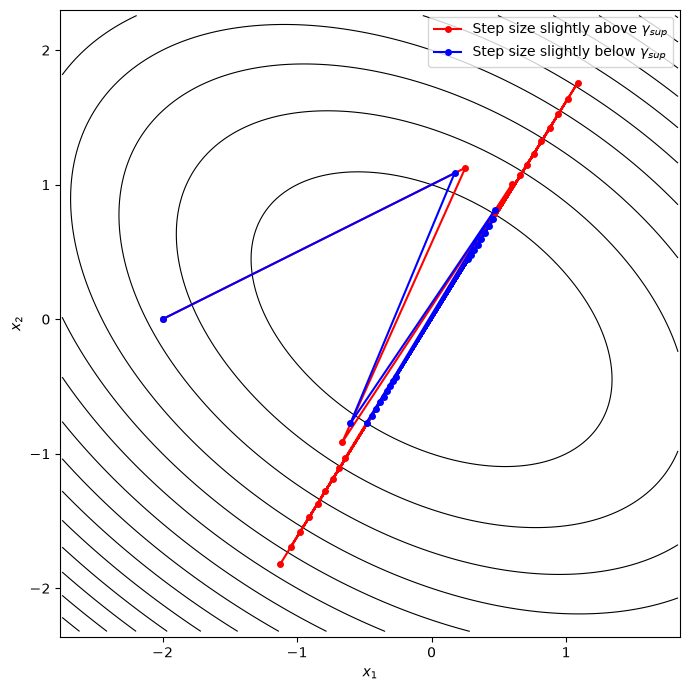

In [47]:
# Convert trajectories to NumPy arrays
def prepare_trajectory(xval):
    xval = np.asarray(xval)
    if xval.ndim == 2 and xval.shape[0] == 2 and xval.shape[1] != 2:
        xval = xval.T
    return xval

x_above = prepare_trajectory(x_above)
x_below = prepare_trajectory(x_below)

# Use matching square bounds for the contour grid and displayed axes.
all_x = np.vstack([x_above, x_below])
x_center = (all_x[:, 0].min() + all_x[:, 0].max()) / 2
y_center = (all_x[:, 1].min() + all_x[:, 1].max()) / 2
half_range = 0.5 * max(np.ptp(all_x[:, 0]), np.ptp(all_x[:, 1])) + 0.5
xmin, xmax = x_center - half_range, x_center + half_range
ymin, ymax = y_center - half_range, y_center + half_range

xx = np.linspace(xmin, xmax, 300)
yy = np.linspace(ymin, ymax, 300)
X, Y = np.meshgrid(xx, yy)

# Evaluate the quadratic objective function on the grid
F = (0.5 * (A[0, 0] * X**2
            + (A[0, 1] + A[1, 0]) * X * Y
            + A[1, 1] * Y**2)
     + b[0] * X + b[1] * Y + c)

# Plot contours
plt.figure(figsize=(7, 7))
plt.contour(X, Y, F, levels=20, colors='black',
            linewidths=0.8)

# Plot gradient descent trajectories
plt.plot(x_above[:, 0], x_above[:, 1], 'o-',
         color='red', markersize=4,
         label=r'Step size slightly above $\gamma_{sup}$')

plt.plot(x_below[:, 0], x_below[:, 1], 'o-',
         color='blue', markersize=4,
         label=r'Step size slightly below $\gamma_{sup}$')

plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.axis('equal')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

The level set plot above shows that the GD algorithm converge painfully slow to the minimum when the step size is slightly below $\gamma_{sup}$. This confirms that the GD algorithm is still stable for $\gamma < \gamma_{sup}$, although the convergence speed is way too slow. We also observe that the GD algorithm is diverging when the step size is slightly above $\gamma_{sup}$. This confirms that the GD algorithm is unstable when $\gamma > \gamma_{sup}$.

Plot the value of objective function over N iteration:

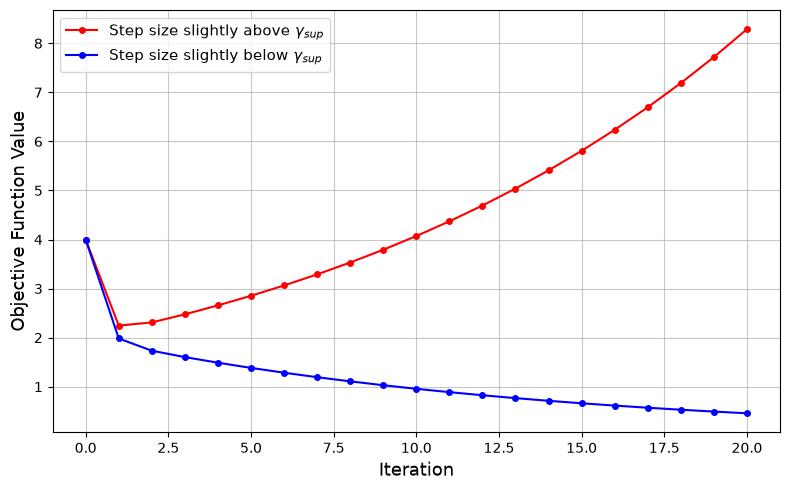

In [48]:
# Plot objective function value against iteration
plt.figure(figsize=(8, 5))

plt.plot(f_above, 'o-', markersize=4, color='red',
         label=r'Step size slightly above $\gamma_{sup}$')

plt.plot(f_below, 'o-', markersize=4, color='blue',
         label=r'Step size slightly below $\gamma_{sup}$')

plt.xlabel('Iteration', fontsize=13)
plt.ylabel('Objective Function Value', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.7)
plt.tight_layout()
plt.show()

The plot above clearly show the effect of step sizes that are close to the stability boundary $\gamma_{\sup}$. When $\gamma < \gamma_{\sup}$, the GD algorithm converge to the minimum (stable, but slow), while for $\gamma > \gamma_{\sup}$, the GD algorithm diverge (unstable). This answer (c).

### Exercise 2-12 (p.86)
Goal: $\textit{To observe and comprehend how the dimension of optimization problem affect runtime and convergence speed.}$

In this experiment we will explore how GD algorithm scales with the dimension of an optimization problem. To simplify analysis we will consider quadratic objective function where we know how to calculate both the range of stable step size and optimal step size.

Consider the following quadratic objective function:

\begin{equation}
    f(\mathbf{x}) = \frac{1}{2}\mathbf{x}^T Q \mathbf{x}
    \tag{1.6}
\end{equation}

where $Q \in \mathbb{R}^{n \times n}$ is a symmetric positive definite matrix. The optimal point is $x^*=0$. We choose the initial condition to be $x_0 = [1,1, ..., 1]^T = \mathbf{1}_n$.

Note that for quadratic objective function (1.6), the gradient vector is $\nabla f(x) = Q \mathbf{x}$, so each iteration computes:

\begin{equation}
    \mathbf{x}_{k+1} = \mathbf{x}_k - \gamma Q \mathbf{x}_k
    \tag{1.7}
\end{equation}

In this experiment, we generate the positive definite matrix $Q=A^T A$ by first generating random rectangular matrix $A \in \mathbb{R}^{m \times n}$, with $m>n$. We need to be able to generate matrix $Q$ of various dimension $n \times n$. As we increase the size of $n$, we will investigate how GD scales with the dimension. One way to do this is by custom eigenvalues:

(a) Compute the SVD of $A$: $A = U \Sigma V^T$.

(b) Assume that the rank of $A$ is $n$, then the eigenvalues $\lambda_i$ of $Q$ will be the square of the non-zero singular values of A, i.e. $\sigma_i^2$.

(c) Thus, to design custom eigenvalues $\hat{\lambda}_i > 0$, we simply replace the corresponding singular values with $\sqrt{\hat{\lambda}_i}$, resulting in $\hat{\Sigma}$. Then we construct a new custom $\hat{A}$ and $\hat{Q}$:

\begin{equation}
    \hat{A} = U \hat{\Sigma} V^T
    \quad \Longrightarrow \quad
    \hat{Q} = \hat{A}^T \hat{A}
    \tag{1.8}
\end{equation}

We choose the eigenvalues of $Q$ in the range $1 \leq \lambda_i(Q) \leq 10$.

Define a function to generate custom positive definite matrix $Q$:

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import time

In [51]:

def generate_Q_custom_eigenvalues(n, lambda_min=1.0, lambda_max=10.0, seed=42):

    if n < 1:
        raise ValueError("n must be positive")
    if not (0 < lambda_min <= lambda_max):
        raise ValueError("Require 0 < lambda_min <= lambda_max")

    rng = np.random.default_rng(seed)

    # 1. Generate a random A with full column rank.
    m = 2 * n
    A = rng.standard_normal((m, n))

    # 2. Compute the reduced SVD: A = U @ diag(s) @ Vt.
    U, s, Vt = np.linalg.svd(A, full_matrices=False)

    # 3. Choose the desired eigenvalues.
    lambda_hat = np.linspace(lambda_min, lambda_max, n)

    # 4. Replace singular values with sqrt of desired eigenvalues.
    Sigma_hat = np.diag(np.sqrt(lambda_hat))

    # 5. Construct the modified A.
    A_hat = U @ Sigma_hat @ Vt

    # 6. Construct Q.
    Q_hat = A_hat.T @ A_hat

    return Q_hat, lambda_hat


We choose $n \in \{10,100,500,1000,2000\}$.

In [52]:
sizes = [10, 100, 500, 1000, 2000]

Qn = {n: generate_Q_custom_eigenvalues(n) for n in sizes}

Define function to create the quadratic objective:

In [53]:
# Define the quadratic objective function.
def quadratic_objective(X,Qn):
    return 0.5 * X.T @ Qn @ X

To measure convergence we use relative error $e_k = \| x_k - x^* \| / \| x_0 - x^* \| \leq 10^{-3}$. Also for safe guard, we set maximum iterations to 10,000 steps.

Define function that implement GD algorithm:

In [54]:
def gradient_descent(Qn, x0, step_size, max_iter=10_000, tol=1e-3):

    x = np.asarray(x0, dtype=float).copy()
    xval = [x.copy()]
    fval = [quadratic_objective(x, Qn)]

    initial_norm = np.linalg.norm(x)
    converged = False
    rel_error = 0.0 if initial_norm == 0 else 1.0
    iterations = 0

    for k in range(max_iter+1):
        # For this objective, x_star = 0.
        rel_error = (
            0.0 if initial_norm == 0
            else np.linalg.norm(x) / initial_norm
        )
        if rel_error <= tol:
            converged = True
            break

        if k == max_iter:
            converged = False
            break

        grad = Qn @ x  # Compute the gradient of objective function.
        x = x - step_size * grad  # Update x using the gradient descent step.
        xval.append(x.copy())
        fval.append(quadratic_objective(x, Qn))
        iterations = k + 1

    return {
        "x_k": np.array(xval),
        "f_xk": np.array(fval),
        "iterations": iterations,
        "relative_error": rel_error,
        "gradient_norm": np.linalg.norm(Qn @ x),
        "converged": converged,
    }

Since runtime can be varied, we run the gradient descent 30 times for each value of $n$, then calculate median of runtime.

Let's initialize the problem and run the GD algorithm as follow:

In [55]:
gamma = 0.01  # Step size
num_runs = 30

iterations_by_n = []
runtime_stats = {"median": [], "mean": []}
results_by_n = {}

for n in sizes:
    Q, eigenvalues = Qn[n]
    x0 = np.ones(n)

    # Warm-up run; keep the convergence results and trajectory.
    result_n = gradient_descent(Q, x0, gamma)
    results_by_n[n] = result_n

    times = []
    
    for _ in range(num_runs):
        start = time.perf_counter()
        gradient_descent(Q, x0, gamma)
        times.append(time.perf_counter() - start)

    iterations_by_n.append(result_n["iterations"])
    runtime_stats["median"].append(np.median(times))
    runtime_stats["mean"].append(np.mean(times))

    print(f"For n={n}:")
    print("Iterations:", result_n["iterations"])
    print("Relative error:", result_n["relative_error"])
    print("Gradient norm:", result_n["gradient_norm"])
    print("Convergence status:", result_n["converged"])
    print(f"Median runtime: {runtime_stats['median'][-1]:.6f} seconds")
    print(f"Mean runtime:   {runtime_stats['mean'][-1]:.6f} seconds")
    print()
    

For n=10:
Iterations: 520
Relative error: 0.000994339349585678
Gradient norm: 0.0031444859621408533
Convergence status: True
Median runtime: 0.009198 seconds
Mean runtime:   0.009661 seconds

For n=100:
Iterations: 445
Relative error: 0.000989685502719578
Gradient norm: 0.01306914295024143
Convergence status: True
Median runtime: 0.009258 seconds
Mean runtime:   0.010271 seconds

For n=500:
Iterations: 471
Relative error: 0.0009968644421361004
Gradient norm: 0.025337690611386122
Convergence status: True
Median runtime: 0.049796 seconds
Mean runtime:   0.056124 seconds

For n=1000:
Iterations: 462
Relative error: 0.0009962176477144758
Gradient norm: 0.035309802238238916
Convergence status: True
Median runtime: 0.166228 seconds
Mean runtime:   0.170661 seconds

For n=2000:
Iterations: 460
Relative error: 0.00099202229275472
Gradient norm: 0.04932221943396295
Convergence status: True
Median runtime: 2.197362 seconds
Mean runtime:   2.197937 seconds



The results shows that the GD algorithm converge for all $n$ based on relative error criteria.

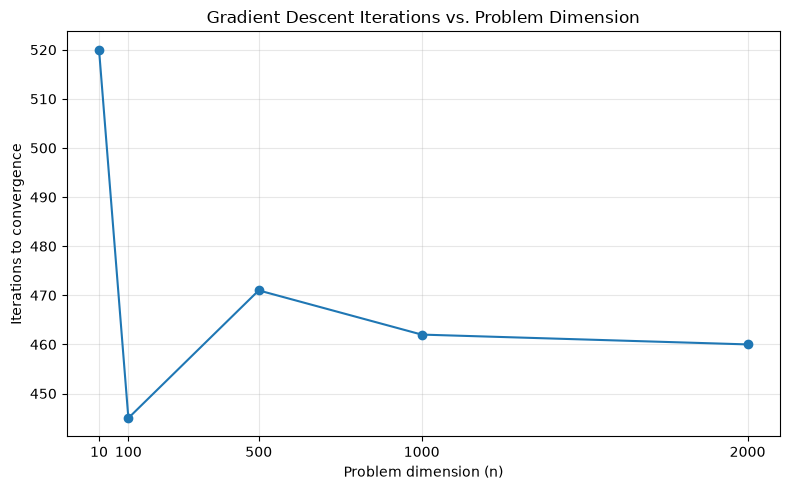

In [56]:
plt.figure(figsize=(8, 5))
plt.plot(sizes, iterations_by_n, "o-")
plt.xlabel("Problem dimension (n)")
plt.ylabel("Iterations to convergence")
plt.title("Gradient Descent Iterations vs. Problem Dimension")
plt.xticks(sizes)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The plot above shows that the number of iterations to converge varies as the dimension $n$ grows.

Initially, the iterations decreases from 520 to 445 as the dimension increase from $n=10$ to $n=100$. But as the dimension grows even larger from $n=10$ to $n=2000$, the iterations does not exhibit clear increasing trend. Instead, the iterations fluctuate within a narrow range between 445 to 471. This suggest that increase in dimension do not necessarily cause increase in GD iterations required to reach prescribed relative error tolerance. In particular, this experiment suggest that iterations are relatively stable for large dimension.

The result can be explained from the theoretical analysis of convergence rate. Recall from equation (1.7) that the GD iteration is given by $\mathbf{x}_{k+1} = (I-\gamma Q) \mathbf{x}_k$. Note that the convergence rate is determined by the spectral radius of $(I-\gamma Q)$, which is the largest absolute eigenvalue $\rho (I-\gamma Q) = \max_i |1-\gamma \lambda_i|$. We can see that the contraction factor does not depend on the dimension $n$, but depend on the eigenvalue of $Q$ (step size is fix). And since in this experiment we set the eigenvalue range fix from $\lambda_{min}=1$ to $\lambda_{max}=10$, the contraction factor is still the same for various value of dimension $n$. This explain why the number of iterations needed to achieve convergence is relatively stable within a narrow range.

Why for $n=10$ the number of iterations is so different ? Although the spectrum of eigenvalues is identical for different $n$, the projection of initial condition $\mathbf{x}_0=\mathbf{1}_n$  for $n=2$ might have very different component along the slowest-decaying eigenvector compared to the other value of $n$. This serve as a plausible explanation for this particular result.

Curve fitting for median runtime:

In [61]:
n = np.asarray(sizes, dtype=float)
T = np.asarray(runtime_stats["median"], dtype=float)

# Keep only dimensions from 100 to 2000
mask = (n >= 100) & (n <= 2000)
n_fit_data = n[mask]
T_fit_data = T[mask]

# Fit log(T) = log(C) + p*log(n)
p, log_C = np.polyfit(
    np.log(n_fit_data),
    np.log(T_fit_data),
    1
)
C = np.exp(log_C)

print(f"Estimated exponent p = {p:.3f}")
print(f"Estimated coefficient C = {C:.6e}")

Estimated exponent p = 1.702
Estimated coefficient C = 2.374312e-06


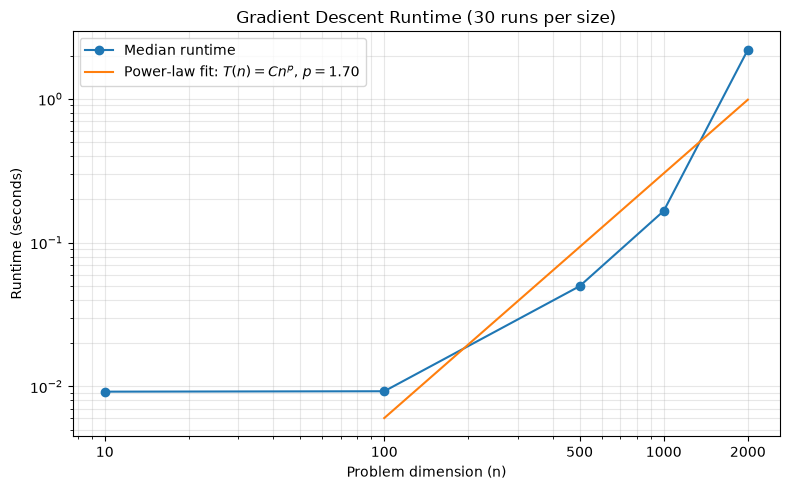

In [62]:
# Generate fitted curve
n_curve = np.geomspace(n_fit_data.min(), n_fit_data.max(), 300)
T_curve = C * n_curve**p

plt.figure(figsize=(8, 5))

plt.loglog(sizes, runtime_stats["median"], "o-", label="Median runtime")
plt.loglog(n_curve, T_curve, "-",
           label=fr"Power-law fit: $T(n)=Cn^p$, $p={p:.2f}$")

plt.xlabel("Problem dimension (n)")
plt.ylabel("Runtime (seconds)")
plt.title(f"Gradient Descent Runtime ({num_runs} runs per size)")
plt.xticks(sizes, sizes)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

The figure above shows log-log plot of median runtime vs dimension $n$ for different problem dimension, based on 30 run for each dimension. We choose median since it is less sensitive to variability of runtime that can be caused by interruption, background process or other system activity.

This result suggest that runtime grows quite rapidly as dimension $n$ increases, as expected. For $n=10$ and $n=100$, the median runtime are nearly identical. One possible explanation is fixed overhead for relatively small dimension, which is a baseline computational cost that does not scale with the size of the dimension. As $n$ grows larger, the dimension-dependent computation (large matrix multiplication) dominates, and runtime grows.

Recall from equation (1.7), the GD updates is given by $ \mathbf{x}_{k+1} = \mathbf{x}_k - \gamma Q \mathbf{x}_k$. For large matrices, the runtime is dominated by matrix-vector multiplication $Qx$ where the computational cost is $O(n^2)$. Thus work per iteration increases quadratically with the problem dimension $n$.

Since Total work $\approx$ work per iteration $\times$ number of iterations and the iterations in the previous experiment is relatively stable for large dimension, then Total work (and thus runtime) is also expected to increase approximately quadratically with $n$. This provide theoretical explanations for the sharp increase in runtime observed at large dimensions.

For $n=10$ to $n=2000$, we fit a scaling law where $T(n)=Cn^p$ where $p=1.73$. The empirical scaling do not follow theoretical quadratic scaling, which can be caused by some factors such as measurement variability, implementation-dependent cost and others.

Let's plot the objective function's value over iteration:

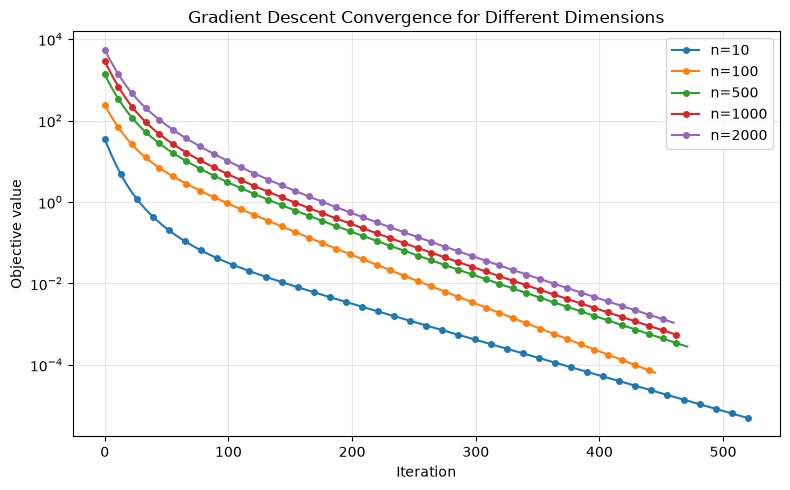

In [63]:
plt.figure(figsize=(8, 5))

for n in sizes:
    f = results_by_n[n]["f_xk"]
    markevery = max(1, len(f) // 40)
    
    plt.semilogy(
        np.arange(len(f)),
        f,
        marker="o",
        markersize=4,
        markevery=markevery,
        label=f"n={n}",
    )

plt.xlabel("Iteration")
plt.ylabel("Objective value")
plt.title("Gradient Descent Convergence for Different Dimensions")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

The plot above show semilog plot of objective function's value versus iterations of GD for different problem dimension. The result clearly show that the iteration undergo transient phase (curved line) starting from the initial condition. This is cause by combined contributions of multiple eigenvalue modes that decay at different rate. 

As the iterations progress, faster-decaying modes become negligible and slower-decaying modes become dominant. Consequently, the decrease of the objective function's value obey geometric decay, which in semilog plot, resulting into a straight line.

Recall that the objective function behaviour can be approximated by $f(x_k) \approx C\rho^k $, with $C>0$ and  $0<\rho<1$. Take the log on both sides: 

\begin{equation*}
    \log f(x_k) \approx \log C + k \log \rho
\end{equation*}

This has the simple form $y = b + mk$, which is a linear function of the iteration $k$ where the intercept is $b=\log C$ and the slope is $m=\log \rho < 0$. Thus the objective function's value decreases linearly in a semilog plot as shown by the figure above, which is consistent with geometric decay of GD algorithm. 

Another interesting result that can be seen from the plot, is that as the dimension $n$ increases, the iterations stops at higher objective function's value. This can be explained from the relative error criteria used to stop the iterations. Recall the relative error criteria:

\begin{equation*}
    \frac{\| \mathbf{x}_k - \mathbf{x}^* \|_2}{\| \mathbf{x}_0 - \mathbf{x}^* \|_2} 
    \leq \varepsilon
\end{equation*}

In our experiment: $\varepsilon=10^{-3}$, optimal point $\mathbf{x}^* = \mathbf{0}$ and initial point $\mathbf{x}_0 = \mathbf{1}_n$. Thus, for iteration at $k$, we have:

\begin{equation*}
    \| \mathbf{x}_k \|_2 \leq 10^{-3} \sqrt{n}
\end{equation*}

The formula tell us that as $n$ increase, then the upper bound on the norm of $\mathbf{x}_k$ also increase proportional to $\sqrt{n}$. This lead to higher objective function's value $f(\mathbf{x}_k)$, as shown in the plot.

## Gradient Descent with Momentum (Heavy Ball)

### Numerical Example (p.50)

Goal:
- $\textit{To observe and comprehen that GD perform poorly near saddle point.}$
- $\textit{To observe and comprehen how HB overcome the problem by using momentum to pass through saddle point.}$

Consider two-dimensional objective function with saddle point:

\begin{equation}
    f(x) = 15 e^{-0.25(x+2)^2} + 0.5 e^{-2(x-2)^2} + x^2 + y^2
\tag{1.9}
\end{equation}

The global minimum is attained at $(x^*,y^*)=(1.0181,0)$, where the value of the objective function is $f(x^*,y^*) \approx 2.6477$.

In [4]:
# Define the two-dimensional objective function.
def objective_function(X):
    x, y = np.asarray(X).reshape(2)
    return 15 * np.exp(-0.25 * (x + 2)**2) + 0.5 * np.exp(-2 * (x - 2)**2) + x**2 + y**2

def gradient(X):
    x, y = np.asarray(X).reshape(2)

    df_dx = (
        -7.5 * (x + 2) * np.exp(-0.25 * (x + 2)**2)
        - 2 * (x - 2) * np.exp(-2 * (x - 2)**2)
        + 2 * x
    )
    df_dy = 2 * y

    return np.array([df_dx, df_dy])

Let's plot the objective function (1.9):

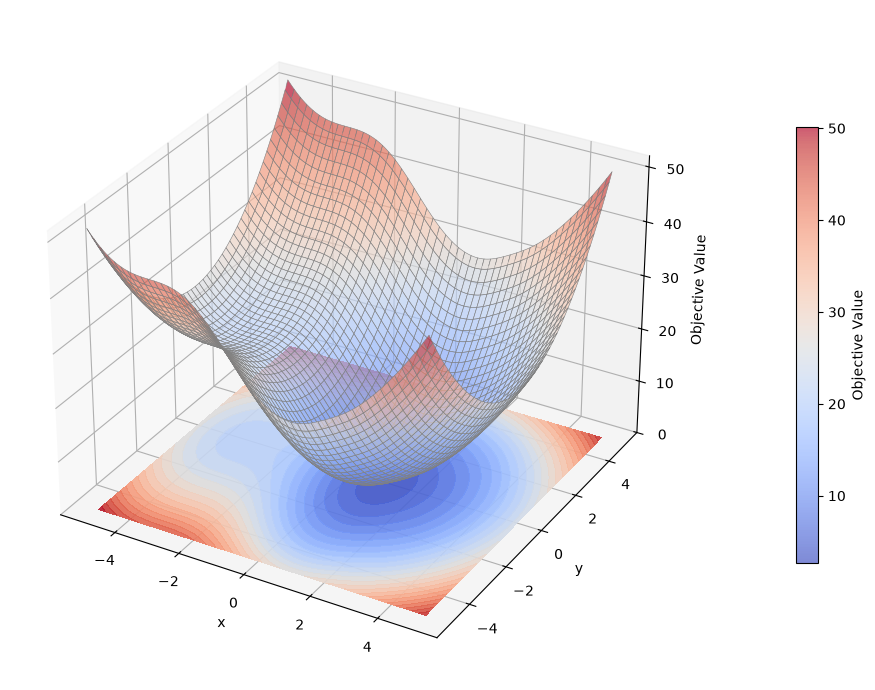

In [5]:
# Evaluate the objective function over a grid of x and y values.
x_values = np.linspace(-5, 5, 200)
y_values = np.linspace(-5, 5, 200)
X_grid, Y_grid = np.meshgrid(x_values, y_values)
Z_grid = (15 * np.exp(-0.25 * (X_grid + 2)**2)
          + 0.5 * np.exp(-2 * (X_grid - 2)**2)
          + X_grid**2 + Y_grid**2)

# Plot the 3D surface and its filled contours on the base plane.
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surface = ax.plot_surface(
    X_grid, Y_grid, Z_grid, cmap='coolwarm',
    edgecolor='gray', linewidth=0.4, alpha=0.65
)
ax.contourf(
    X_grid, Y_grid, Z_grid, zdir='z', offset=0,
    levels=30, cmap='coolwarm', alpha=0.9
)
fig.colorbar(surface, ax=ax, shrink=0.65, pad=0.12, label='Objective Value')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('Objective Value')
ax.set_zlim(0, 52)
ax.view_init(elev=30, azim=-60)
plt.tight_layout()
plt.show()

As we can see from the 3D plot above, there are two minima: one of them is local and the other one is global. Between the two minima, there exist a saddle point where the curvature is positive in one direction and negative in the other orthogonal direction.

Let's define first the GD function:

In [6]:
# Define the GD algorithm. The function return x_k and f(x_k).
def gradient_descent(X0, step_size, max_iter):
    xval = [np.array(X0)] # Initialize with X0 for plotting
    fval = [objective_function(np.array(X0))] # Initialize with f(X0) for plotting.
    X = np.array(X0, dtype=float) # Initialize with X0 for iteration.

    for _ in range(max_iter):
        grad = gradient(X)  # Compute the gradient of objective function.
        X = X - step_size * grad  # Update X using the gradient descent step.
        xval.append(X.copy())  # Store the current X for plotting.
        fval.append(objective_function(X))  # Store the current function value for plotting.
    return np.array(xval), np.array(fval)  # Return the arrays of x values and function values for plotting.

Let's choose an initial point, step-size and maximum iteration, then run the GD algorithm:

In [7]:
# Set the input for the gradient descent algorithm.
X0 = np.array([-5.0,3.0]) # Initial point.
gamma = 0.1 # Step size.
N = 100 # Maximum iterations.

# Run gradient descent for each step size:
x, f = gradient_descent(X0, gamma, N)

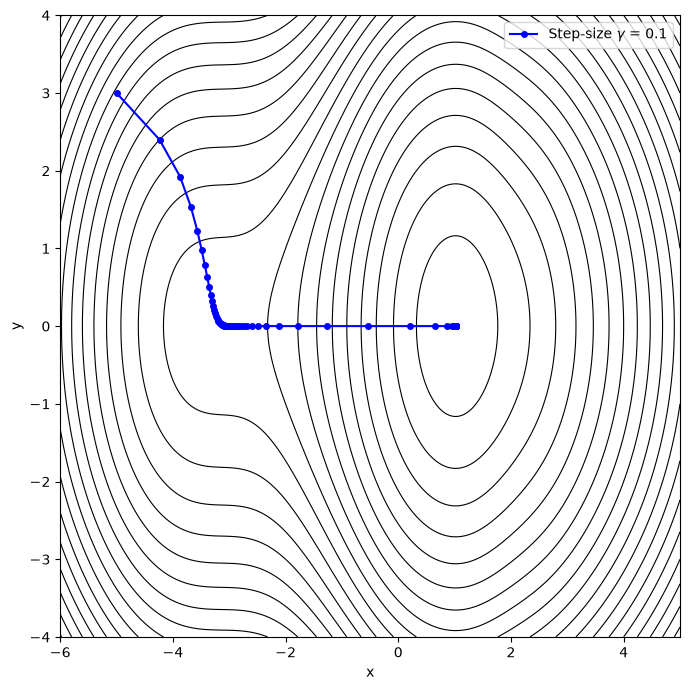

In [8]:
# Create a grid and evaluate the objective function on it.
x_grid = np.linspace(-6, 5, 400)
y_grid = np.linspace(-4, 4, 300)
XX, YY = np.meshgrid(x_grid, y_grid)
FF = (15 * np.exp(-0.25 * (XX + 2)**2)
      + 0.5 * np.exp(-2 * (XX - 2)**2)
      + XX**2 + YY**2)

# Plot the objective function's contours and the GD path.
plt.figure(figsize=(7, 7))
plt.contour(XX, YY, FF, levels=30, colors='black', linewidths=0.8)
plt.plot(x[:, 0], x[:, 1], 'o-', color='blue', markersize=4,
         label=r'Step-size $\gamma$ = 0.1')
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.gca().set_aspect('auto')
plt.tight_layout()
plt.show()

The level set above shows that starting form initial condition (-5,3), the GD algorithm struggles near the saddle point, as the gradient at the saddle point nearly vanishes, causing the iteration converge painfully slow to the global minimum.

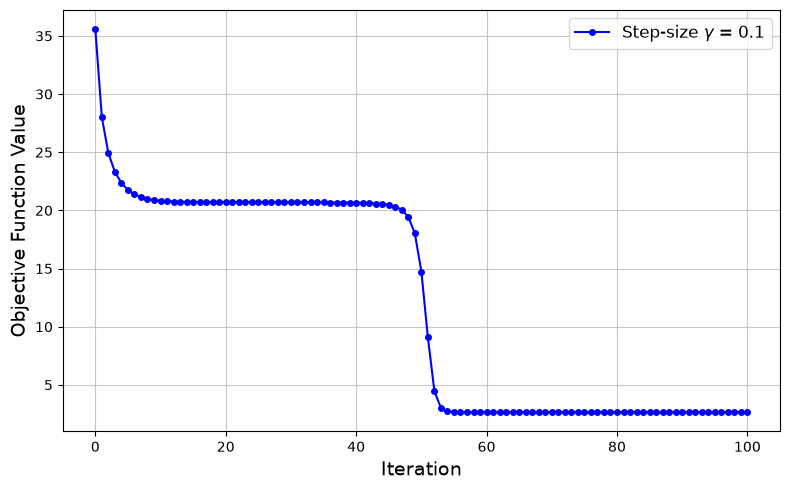

In [9]:
# Plot the objective values returned by gradient_descent.
plt.figure(figsize=(8, 5))
plt.plot(f, 'o-', color='blue', markersize=4,
         label=r'Step-size $\gamma$ = 0.1')
plt.xlabel('Iteration', fontsize=14)
plt.ylabel('Objective Function Value', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.7)
plt.tight_layout()
plt.show()

Here, we can see from the plot above where GD algorithm have difficulty to escape from saddle point since the gradient there may be negligibly small. Recall that GD algorithm is based on current gradient to take the next step, thus small gradient around saddle point result in small step for the next iteration. This pose serious problem for the GD algorithm as it struggle to go past through saddle point to find the minimum.

The classical momentum method or Heavy Ball (HB) address this issue by integrates past gradient and thus provide momentum to the optimization algorithm such that it can go pass through saddle point of small gradient and converge toward the minimum.

The code below implement HB algorithm:

In [10]:
# Define the HB algorithm. The function return x_k and f(x_k).
def heavy_ball(X0, decay_rate, step_size, max_iter):
    xval = [np.array(X0)] # Initialize with X0 for plotting
    fval = [objective_function(np.array(X0))] # Initialize with f(X0) for plotting.
    X = np.array(X0, dtype=float) # Initialize with X0 for iteration.
    V = np.zeros_like(X)  # Initialize zero velocity term.

    for _ in range(max_iter):
        grad = gradient(X)  # Compute the gradient of objective function.
        V = decay_rate * V - step_size * grad  # Update the velocity term.
        X = X + V  # Update X using the heavy ball step.
        xval.append(X.copy())  # Store the current X for plotting.
        fval.append(objective_function(X))  # Store the current function value for plotting.
    return np.array(xval), np.array(fval)  # Return the arrays of x values and function values for plotting.

Let's set the input for HB algorithm which include decay rate $\beta=0.6$ and the same step size $\gamma=0.1$ , then run the HB algorithm.

In [12]:
# Set the input for the HB algorithm.
X0 = np.array([-5.0,3.0]) # Initial point.
decay_rate = 0.6 # Decay rate.
gamma = 0.1 # Step size.
N = 100 # Maximum iterations.

# Run heavy ball for each step size:
x_hb, f_hb = heavy_ball(X0, decay_rate, gamma, N)

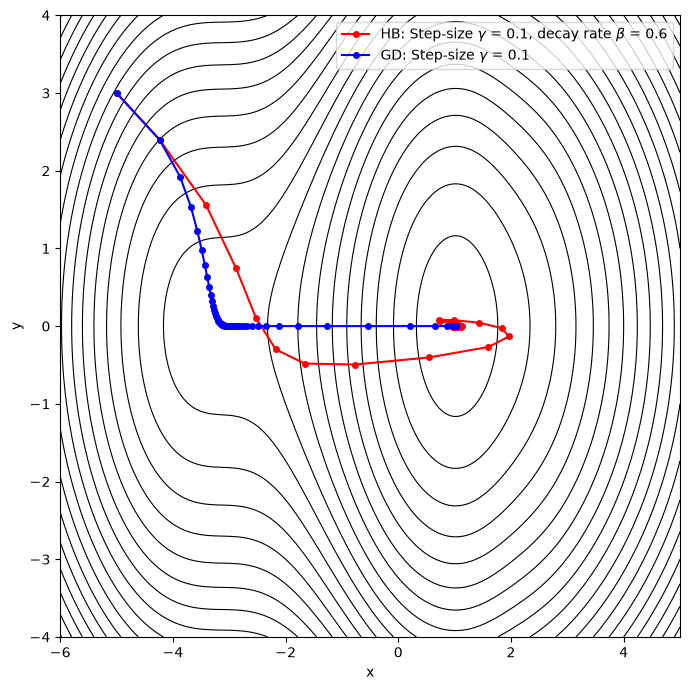

In [15]:
# Create a grid and evaluate the objective function on it.
x_grid = np.linspace(-6, 5, 400)
y_grid = np.linspace(-4, 4, 300)
XX, YY = np.meshgrid(x_grid, y_grid)
FF = (15 * np.exp(-0.25 * (XX + 2)**2)
      + 0.5 * np.exp(-2 * (XX - 2)**2)
      + XX**2 + YY**2)

# Plot the objective function's contours and the HB path.
plt.figure(figsize=(7, 7))
plt.contour(XX, YY, FF, levels=30, colors='black', linewidths=0.8)

plt.plot(x_hb[:, 0], x_hb[:, 1], 'o-', color='red', markersize=4,
         label=r'HB: Step-size $\gamma$ = 0.1, decay rate $\beta$ = 0.6')

plt.plot(x[:, 0], x[:, 1], 'o-', color='blue', markersize=4,
         label=r'GD: Step-size $\gamma$ = 0.1')

plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.gca().set_aspect('auto')
plt.tight_layout()
plt.show()

The level set plot above show both GD and HB iteration for comparison. It can be seen clearly that the HB algorithm outperform GD with the same step size. While GD algorithm struggle near saddle point, the HB algorithm can pass through saddle point quite easily. By integrating pass gradients, the HB iteration have enough momentum to pass through saddle point although saddle point have small gradient.

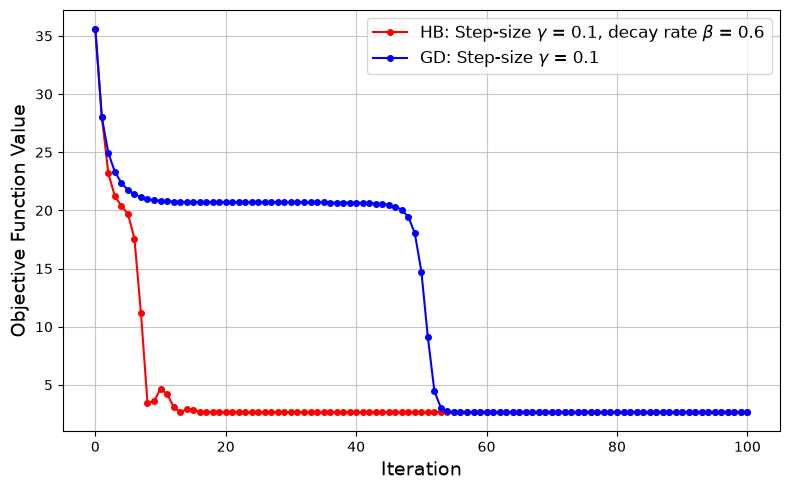

In [18]:
# Plot the objective values returned by heavy_ball.
plt.figure(figsize=(8, 5))

plt.plot(f_hb, 'o-', color='red', markersize=4,
         label=r'HB: Step-size $\gamma$ = 0.1, decay rate $\beta$ = 0.6')

plt.plot(f, 'o-', color='blue', markersize=4,
         label=r'GD: Step-size $\gamma$ = 0.1')

plt.xlabel('Iteration', fontsize=14)
plt.ylabel('Objective Function Value', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.7)
plt.tight_layout()
plt.show()

The plot above show that the HB algorithm converge to the minimum much faster compared to the GD algorithm for the same step size. While the HB already reach the minimum, GD still struggle around the saddle point. This stark contrast between HB and GD in terms of ability to pass through saddle point demonstrate the eminence of integrating past gradients instead of just using current gradient.

By choosing decay rate $\beta=0.6$, this provide the HB algorithm just enough momentum to pass through saddle point while at the same maintain good convergence behaviour toward the minimum.

### Exercise 2-4 (p.85)
Goal:$\textit{To observe and comprehend how HB gain momentumin in areas of high gradient such that it can escape local minimum.}$

Previously, we already see how GD algorithm struggle near saddle point. This problem is addressed by the HB algorithm that integrates past gradients and hence provide momentum such that the iteration can move pass through saddle point that have vanishingly small gradient.

In this exercise we will experiment more with the HB algorithm. Consider the following objective function:

\begin{equation}
    f(x) = \sin^2(x) + 0.1 x^2
    \tag{1.10}
\end{equation}

Let's define the function first then plot it.

In [20]:
# Define and plot the objective function from equation (1.6).
def nonconvex_objective(x):
    return np.sin(x)**2 + 0.1 * x**2

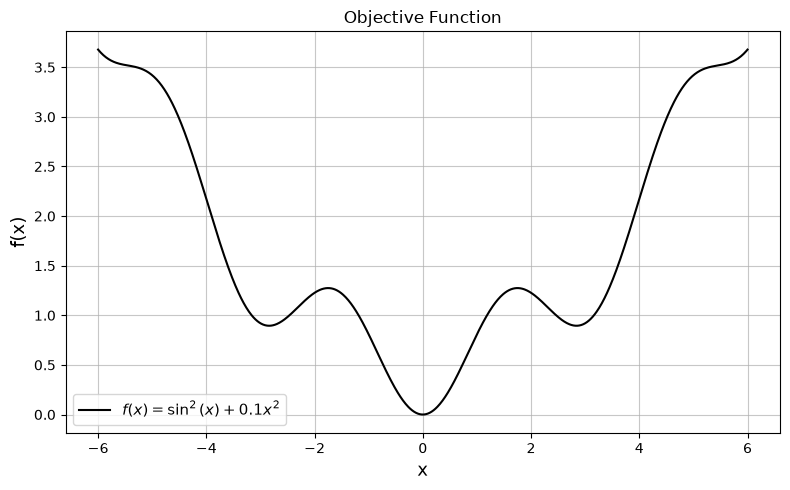

In [21]:
x = np.linspace(-6, 6, 1000)
y = nonconvex_objective(x)

plt.figure(figsize=(8, 5))
plt.plot(x, y, color="black", label=r"$f(x)=\sin^2(x)+0.1x^2$")
plt.xlabel("x", fontsize=13)
plt.ylabel("f(x)", fontsize=13)
plt.title("Objective Function")
plt.grid(True, alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

The objective function  is obviously non-convex, where there are several local minimum and one unique global minimum. The global minimum is attained at $x^*=0$ where $f(x^*)=0$.

In [22]:
# Define the GD algorithm. The function return x_k and f(x_k).
def gradient_descent(x0, step_size, max_iter):
    xval = [np.array(x0)] # Initialize with x0 for plotting
    fval = [nonconvex_objective(np.array(x0))] # Initialize with f(x0) for plotting. 
    x = np.array(x0, dtype=float) # Initialize with x0 for iteration.

    for _ in range(max_iter):
        grad = 2*np.sin(x)*np.cos(x) + 0.2*x  # Compute the gradient of objective function.
        x = x - step_size * grad  # Update x using the gradient descent step.
        xval.append(x.copy())  # Store the current x for plotting.
        fval.append(nonconvex_objective(x))  # Store the current function value for plotting.
    return np.array(xval), np.array(fval)  # Return the arrays of x values and function values for plotting.

Run GD algorithm. Lets see how it behaves on a nonconvex objective function.

In [23]:
x0_1 = np.array([1.0]) # Initial point.
x0_2 = np.array([2.0]) # Initial point.
x0_3 = np.array([5.0]) # Initial point. 

gamma = 0.3 # Step size.
N = 10 # Maximum iterations.

# Run gradient descent:
x1, f1 = gradient_descent(x0_1, gamma, N)
x2, f2 = gradient_descent(x0_2, gamma, N)
x3, f3 = gradient_descent(x0_3, gamma, N)

Let's plot the objective function's value over the iteration :

<>:18: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:18: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
C:\Users\wsnpr\AppData\Local\Temp\ipykernel_8960\1552898539.py:18: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
  plt.title("Gradient Descent on Non-convex Objective Function ($\gamma=0.3$)")


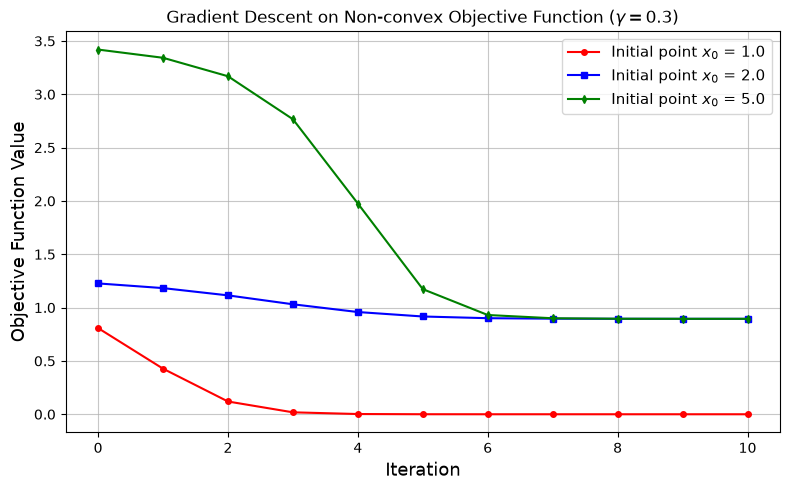

In [28]:
# Plot objective function value against iteration.
iterations = np.arange(len(f1))

plt.figure(figsize=(8, 5))

plt.plot(iterations, f1, "o-", markersize=4, color="red",
         label=r'Initial point $x_0$ = 1.0')

plt.plot(iterations, f2, "s-", markersize=4, color="blue",
         label=r'Initial point $x_0$ = 2.0')

plt.plot(iterations, f3, "d-", markersize=4, color="green",
         label=r'Initial point $x_0$ = 5.0')


plt.xlabel("Iteration", fontsize=13)
plt.ylabel("Objective Function Value", fontsize=13)
plt.title("Gradient Descent on Non-convex Objective Function ($\gamma=0.3$)")
plt.legend(fontsize=11)
plt.grid(True, alpha=0.7)
plt.tight_layout()
plt.show()

The plot above show that when applying GD algorithm to nonconvex objective funtion, then the result will strongly depend on the initial point. The GD algorithm have tendency to converge to the nearest local minimum, hence it will converge to global minimum only when the initial point is sufficiently close to the global minimum.

Will HB algorithm with momentum be able to escape from local minimum to converge to the global minimum ? Let's put it to test.

In [27]:
# Define the HB algorithm. The function return x_k and f(x_k).
def heavy_ball(x0, decay_rate, step_size, max_iter):
    xval = [np.array(x0)] # Initialize with x0 for plotting
    fval = [nonconvex_objective(np.array(x0))] # Initialize with f(x0) for plotting.
    x = np.array(x0, dtype=float) # Initialize with x0 for iteration.
    v = np.zeros_like(x)  # Initialize zero velocity term.

    for _ in range(max_iter):
        grad = 2*np.sin(x)*np.cos(x) + 0.2*x  # Compute the gradient of objective function.
        v = decay_rate * v - step_size * grad  # Update the velocity term.
        x = x + v  # Update x using the heavy ball step.
        xval.append(x.copy())  # Store the current x for plotting.
        fval.append(nonconvex_objective(x))  # Store the current function value for plotting.
    return np.array(xval), np.array(fval)  # Return the arrays of x values and function values for plotting.

What's interesting is the following experiment: if we set the initial condition $x_0=5$, then negative gradient will always point to the left until we reach the local minimum where the gradieny is zero. Can the HB algorithm gain enough momentum along this path to passes through the local minimum and then  reach the global minimum ? Let's conduct the experiment.

In [35]:
# Set the input for the HB algorithm.
x0_1 = np.array([1.0]) # Initial point.
x0_2 = np.array([5.0]) # Initial point. 

decay_rate_good = 0.7 # Decay rate.
decay_rate_small = 0.6 # Decay rate.
decay_rate_large = 0.9 # Decay rate.

gamma = 0.3 # Step size.
N = 30 # Maximum iterations.

# Run heavy ball for each initial point:
x_hb1, f_hb1 = heavy_ball(x0_1, decay_rate_good, gamma, N)

x_hb2, f_hb2 = heavy_ball(x0_2, decay_rate_good, gamma, N)
x_hb3, f_hb3 = heavy_ball(x0_2, decay_rate_small, gamma, N)
x_hb4, f_hb4 = heavy_ball(x0_2, decay_rate_large, gamma, N)

Let's plot the objective function's value over the iteration for each initial point:

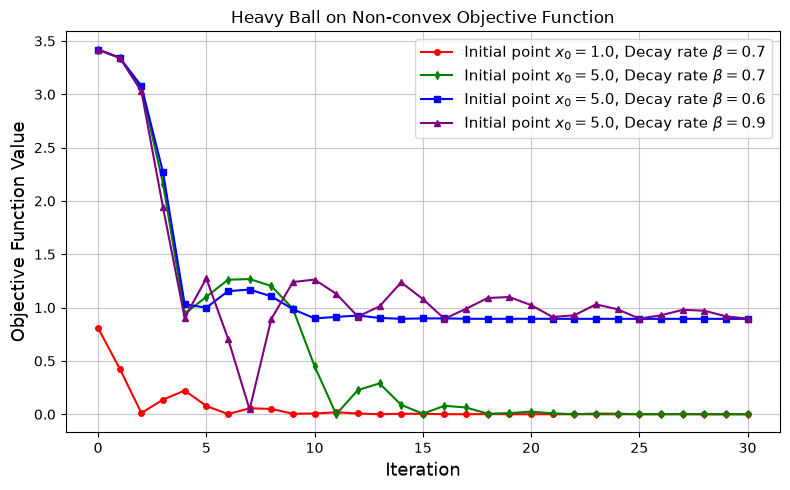

In [37]:
# Plot objective function value against iteration for each initial point.
iterations = np.arange(len(f_hb1))

plt.figure(figsize=(8, 5))

plt.plot(iterations, f_hb1, "o-", markersize=4, color="red",
         label=r"Initial point $x_0=1.0$, Decay rate $\beta=0.7$")

plt.plot(iterations, f_hb2, "d-", markersize=4, color="green",
         label=r"Initial point $x_0=5.0$, Decay rate $\beta=0.7$")

plt.plot(iterations, f_hb3, "s-", markersize=4, color="blue",
         label=r"Initial point $x_0=5.0$, Decay rate $\beta=0.6$")

plt.plot(iterations, f_hb4, "^-", markersize=4, color="purple",
         label=r"Initial point $x_0=5.0$, Decay rate $\beta=0.9$")

plt.xlabel("Iteration", fontsize=13)
plt.ylabel("Objective Function Value", fontsize=13)
plt.title("Heavy Ball on Non-convex Objective Function")
plt.legend(fontsize=11)
plt.grid(True, alpha=0.7)
plt.tight_layout()
plt.show()

The plot above show some very interesting behaviour of HB algorithm. When the initial point is close to the global minimum ($x_0=1$), the HB iteration converge to the global minimum with a bit of oscillation caused by the inherent momentum of iterate $x_k$. 

More interesting behaviour is shown when the algorithm start far from the global minimum. In this case, to reach the global minimum, the iterate $x_k$ must go pass through the local minimum. If we set small decay rate ($\beta=0.6$), the blue line show that the iteration stuck at the local minimum. If we set higher decay rate ($\beta=0.9$), the purple line show us that the iterate gain too much momentum it pass through the local minimum, then it gain even more momentum such that it passes through the global minimum, climb up and then stuck again at the next local minimum.

Finally, when the decay rate is good enough ($\beta=0.7$) as shown by the green line, the iteration have enough momentum to passes through the local minimum, then converge with a bit of oscillation to the global minimum.

This experiment shows that unlike GD, the HB algorithm depend less to initial condition, but depend more on the value of decay rate $\beta$. Larger decay rate give more momentum, and vice versa.